# HOMEWORK 14

In this homework you are going to build your first classifier for the CIFAR-10 dataset. This dataset contains 10 different classes and you can learn more about it [here](https://www.cs.toronto.edu/~kriz/cifar.html). This homework consists of the following tasks:
* Dataset inspection
* Building the network
* Training
* Evaluation

At the end, as usual, there will be a couple of questions for you to answer :-)

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

from time import time
import numpy as np
import keras
from keras import Model
from keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(1234)

### Step 0: Dataset Inspection

Load the dataset and make a quick inspection.

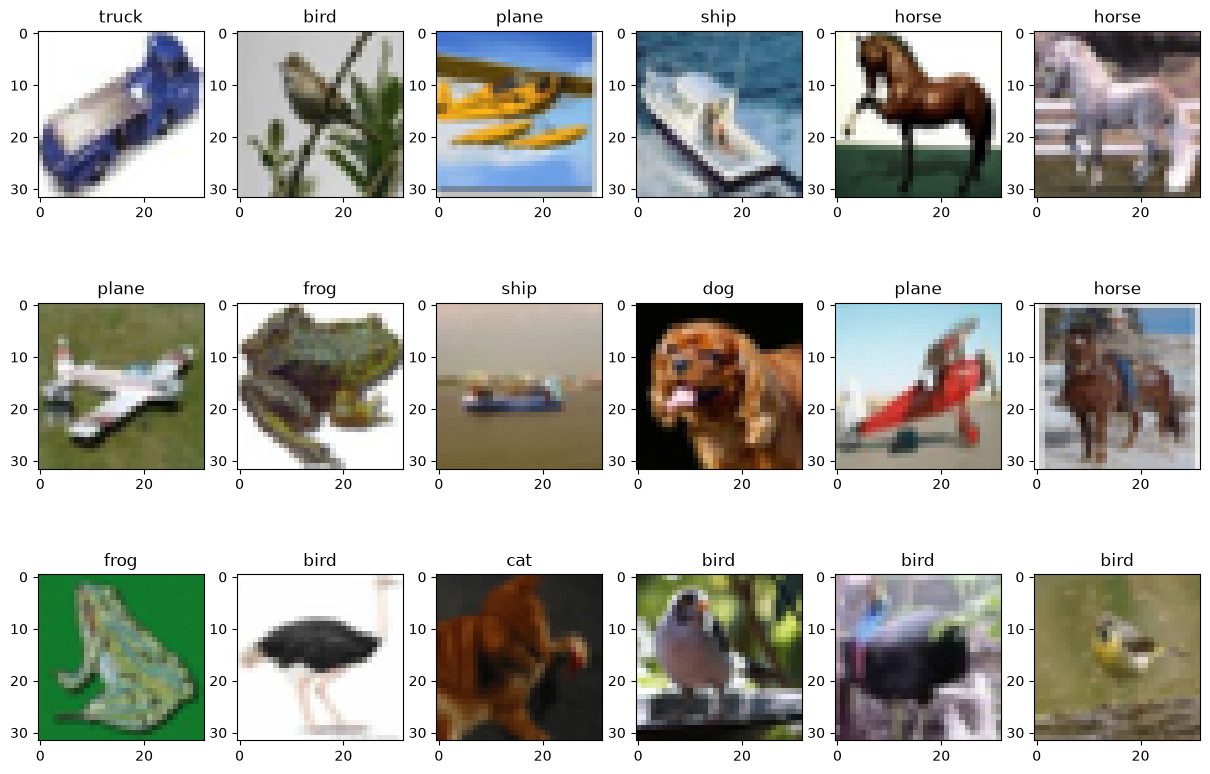

In [2]:
# Load the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
# The labels come as (N, 1) arrays, flatten them to (N,)
y_train, y_test = y_train.flatten(), y_test.flatten()
# Mapping from class ID to class name
classes = {0:'plane', 1:'car', 2:'bird', 3:'cat', 4:'deer',
           5:'dog', 6:'frog', 7:'horse', 8:'ship', 9:'truck'}

# Dataset params
num_classes = len(classes)
size = x_train.shape[1]

# Visualize random samples (as a plot with 3x6 samples)
for ii in range(18):    
    plt.subplot(3,6,ii+1)
    # Pick a random sample
    idx = np.random.randint(0, len(x_train))
    # Show the image and the label
    plt.imshow(x_train[idx, ...])
    plt.title(classes[y_train[idx]])

Compute the class histogram (you can visualize it if you want). Is the dataset balanced?

Hint: You might find [Counter](https://docs.python.org/3/library/collections.html#collections.Counter) tool useful. In any case, it's up to you how you compute the histogram.

(Text(0.5, 0, 'class_id'), Text(0, 0.5, 'Counts'))

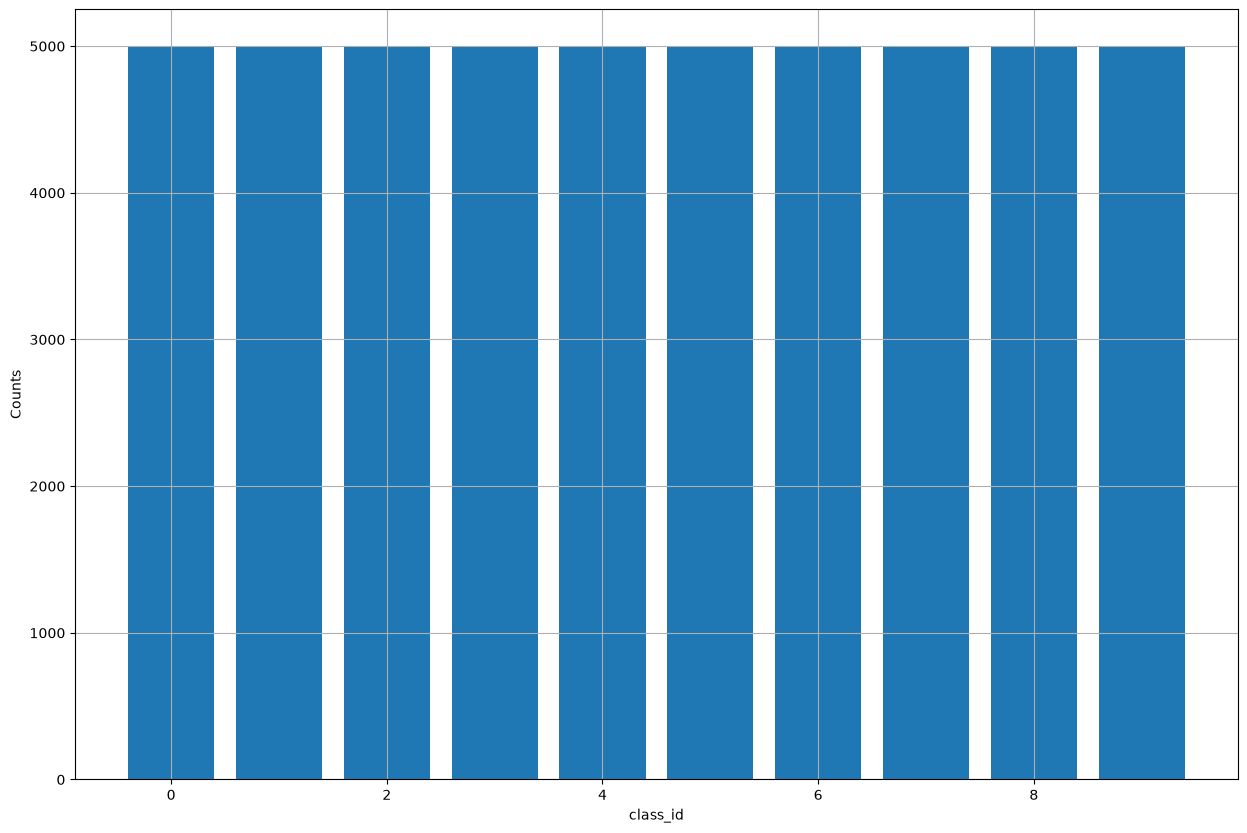

In [3]:
# Compute the class histogram
from collections import Counter
hist = Counter(y_train)

plt.bar(hist.keys(), hist.values()), plt.grid(True)
plt.xlabel('class_id'), plt.ylabel('Counts')

The histogram shows that the given dataset is perfectly balanced which can work good.

### Step 1: Data Preparation

In this step, you'll need to prepare the data for training, i.e., you will have to normalize it and encode the labels as one-hot vectors.

In [4]:
# Normalization
x_train = x_train / 255
x_test = x_test / 255

# One-hot encoding
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)

Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


### Step 2: Building the Classifier

Build the CNN for CIFAR10 classification. For starters, you can use the same network we used in the lesson for the MNIST problem.

Note that, unlike MNIST, the CIFAR-10 images are color (RGB) images.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,770 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,538 (33.35 KB)

 Trainable params: 8,538 (33.35 KB)

 Non-trainable params: 0 (0.00 B)

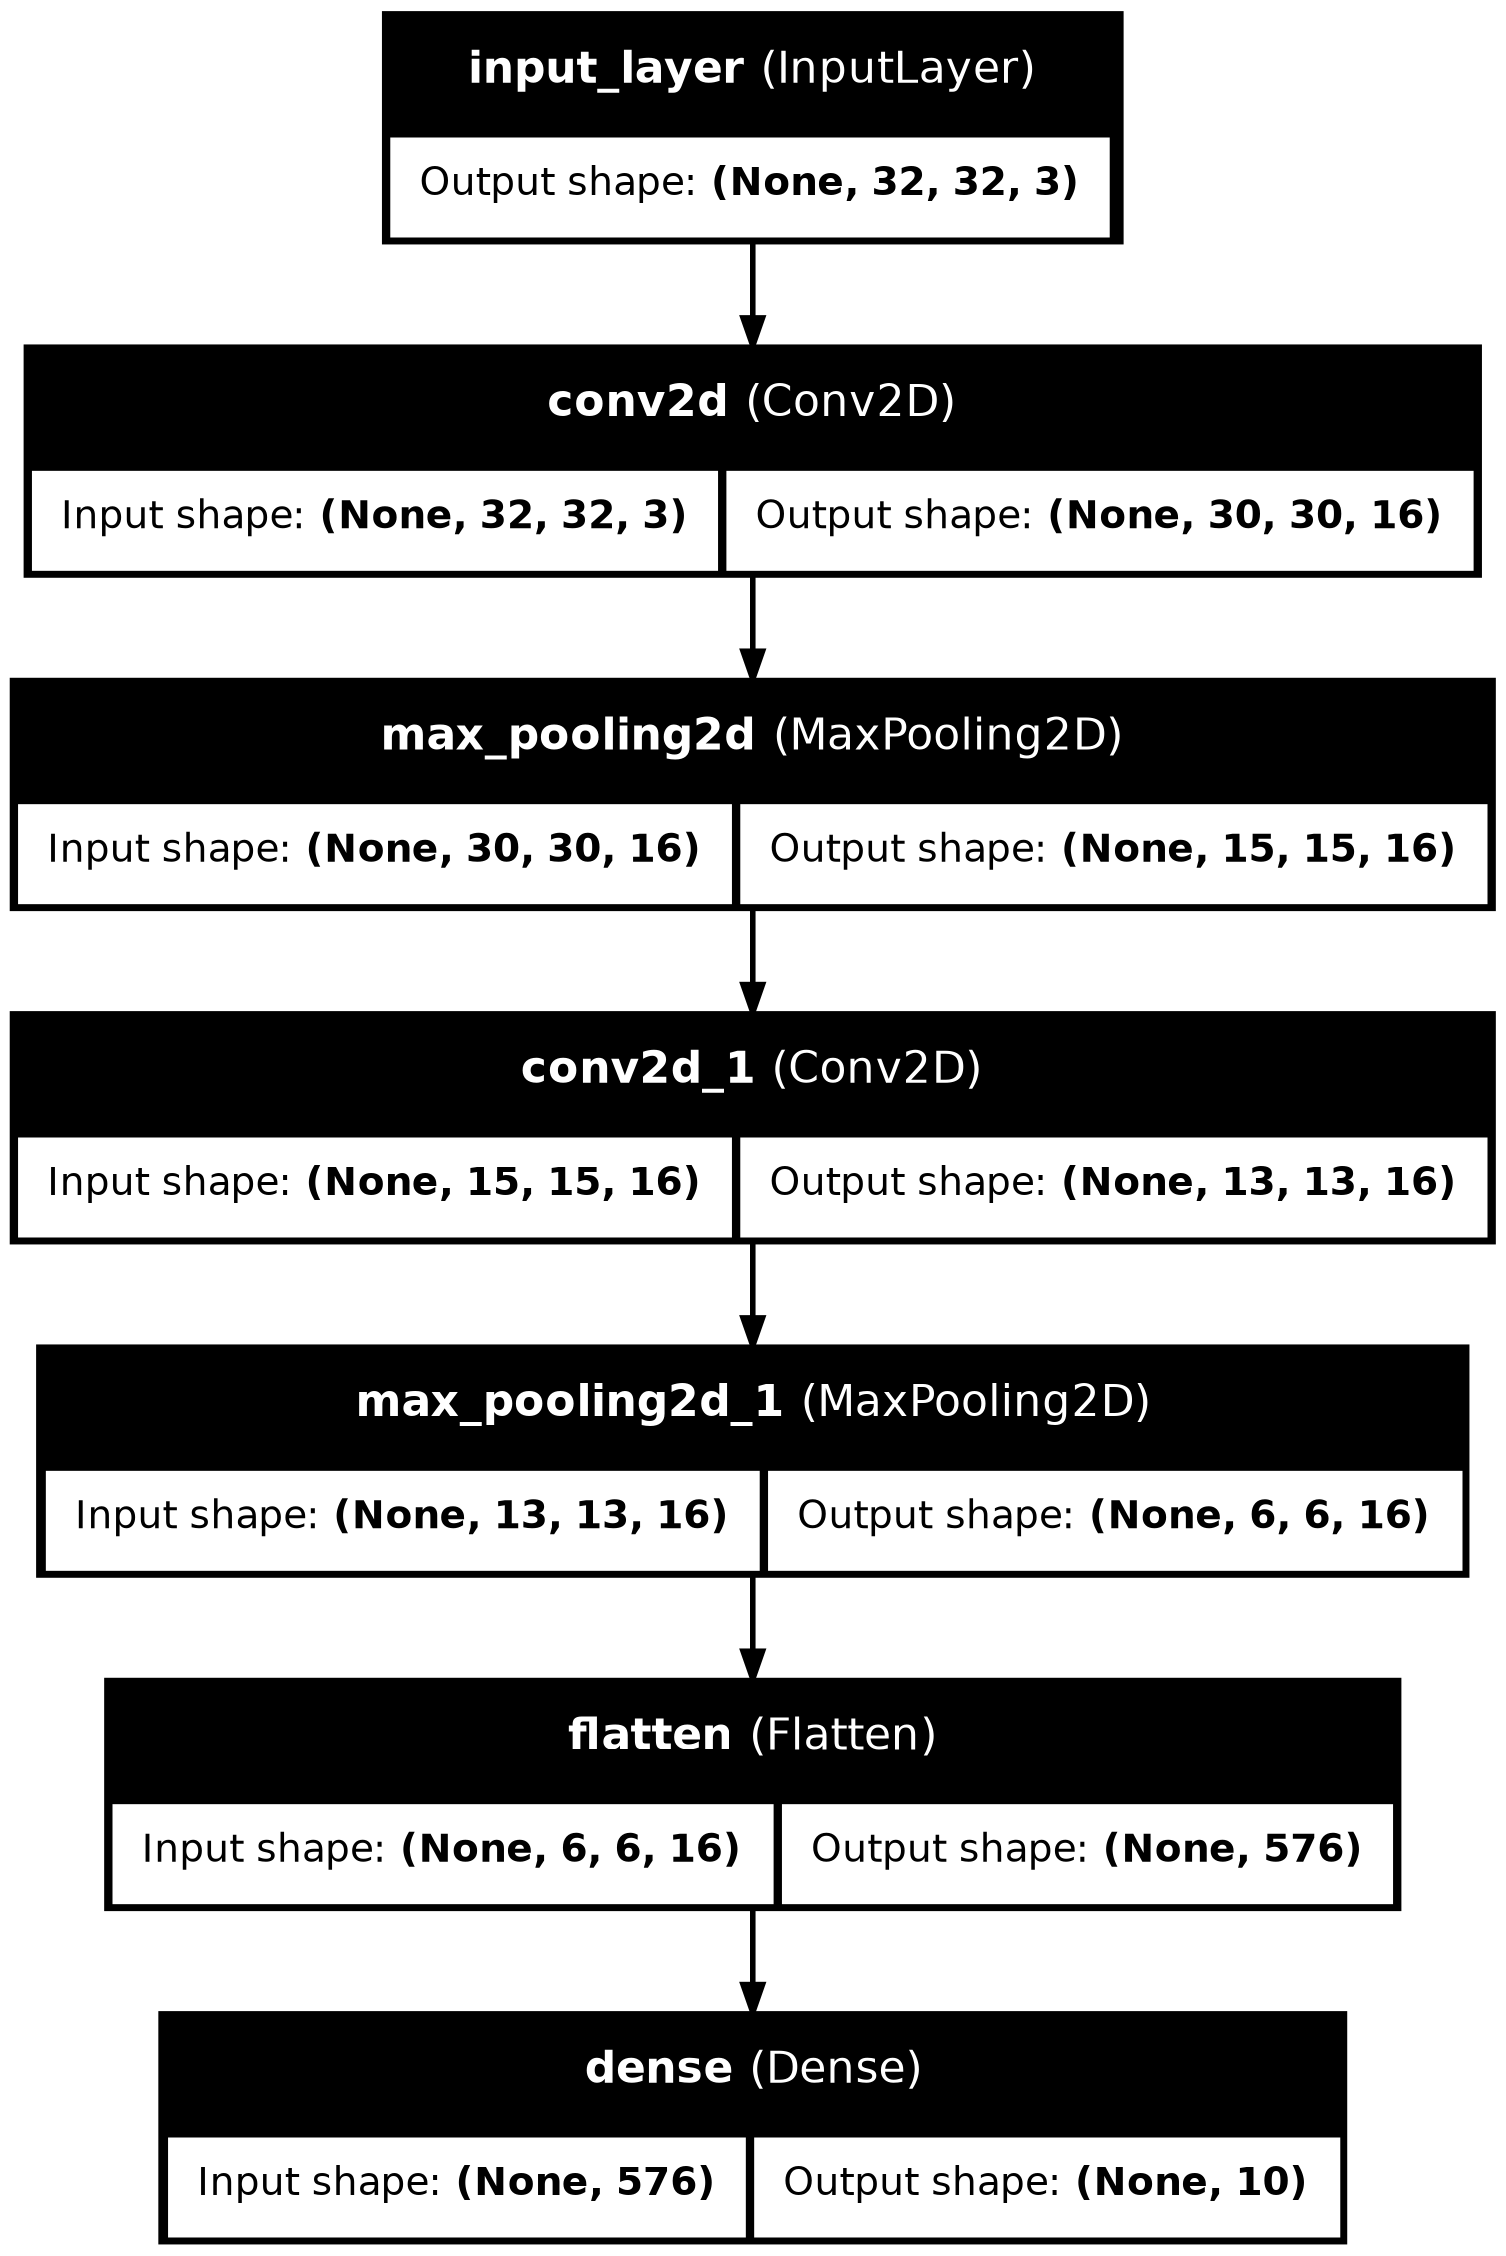

In [5]:
# Build the classifier
size = x_train.shape[1]
inputs = Input(shape=(size, size, 3))
net = Conv2D(16, kernel_size=(3,3), activation='relu')(inputs)
net = MaxPooling2D(pool_size=(2,2))(net)
net = Conv2D(16, kernel_size=(3,3), activation='relu')(net)
net = MaxPooling2D(pool_size=(2,2))(net)
net = Flatten()(net)
outputs = Dense(num_classes, activation='softmax')(net)

model = Model(inputs, outputs)
# Show the model
model.summary()
keras.utils.plot_model(model, to_file="model.png", show_shapes=True, show_layer_names=True)

### Step 3: Training

Compile the model and train it.

In [6]:
epochs = 25
batch_size = 128

# Compile the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
# Train the model
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1, verbose=2)

Epoch 1/25
352/352 - 56s - 159ms/step - accuracy: 0.3574 - loss: 1.7827 - val_accuracy: 0.4542 - val_loss: 1.5458
Epoch 2/25
352/352 - 50s - 141ms/step - accuracy: 0.4764 - loss: 1.4651 - val_accuracy: 0.5016 - val_loss: 1.3968
Epoch 3/25
352/352 - 50s - 141ms/step - accuracy: 0.5174 - loss: 1.3671 - val_accuracy: 0.5324 - val_loss: 1.3163
Epoch 4/25
352/352 - 52s - 147ms/step - accuracy: 0.5406 - loss: 1.3039 - val_accuracy: 0.5566 - val_loss: 1.2661
Epoch 5/25
352/352 - 52s - 146ms/step - accuracy: 0.5580 - loss: 1.2652 - val_accuracy: 0.5660 - val_loss: 1.2394
Epoch 6/25
352/352 - 52s - 148ms/step - accuracy: 0.5704 - loss: 1.2353 - val_accuracy: 0.5754 - val_loss: 1.2230
Epoch 7/25
352/352 - 52s - 148ms/step - accuracy: 0.5774 - loss: 1.2133 - val_accuracy: 0.5828 - val_loss: 1.1994
Epoch 8/25
352/352 - 52s - 146ms/step - accuracy: 0.5883 - loss: 1.1845 - val_accuracy: 0.5932 - val_loss: 1.1719
Epoch 9/25
352/352 - 52s - 147ms/step - accuracy: 0.5961 - loss: 1.1651 - val_accuracy: 

Train Acc      0.6623555421829224
Validation Acc 0.6403999924659729


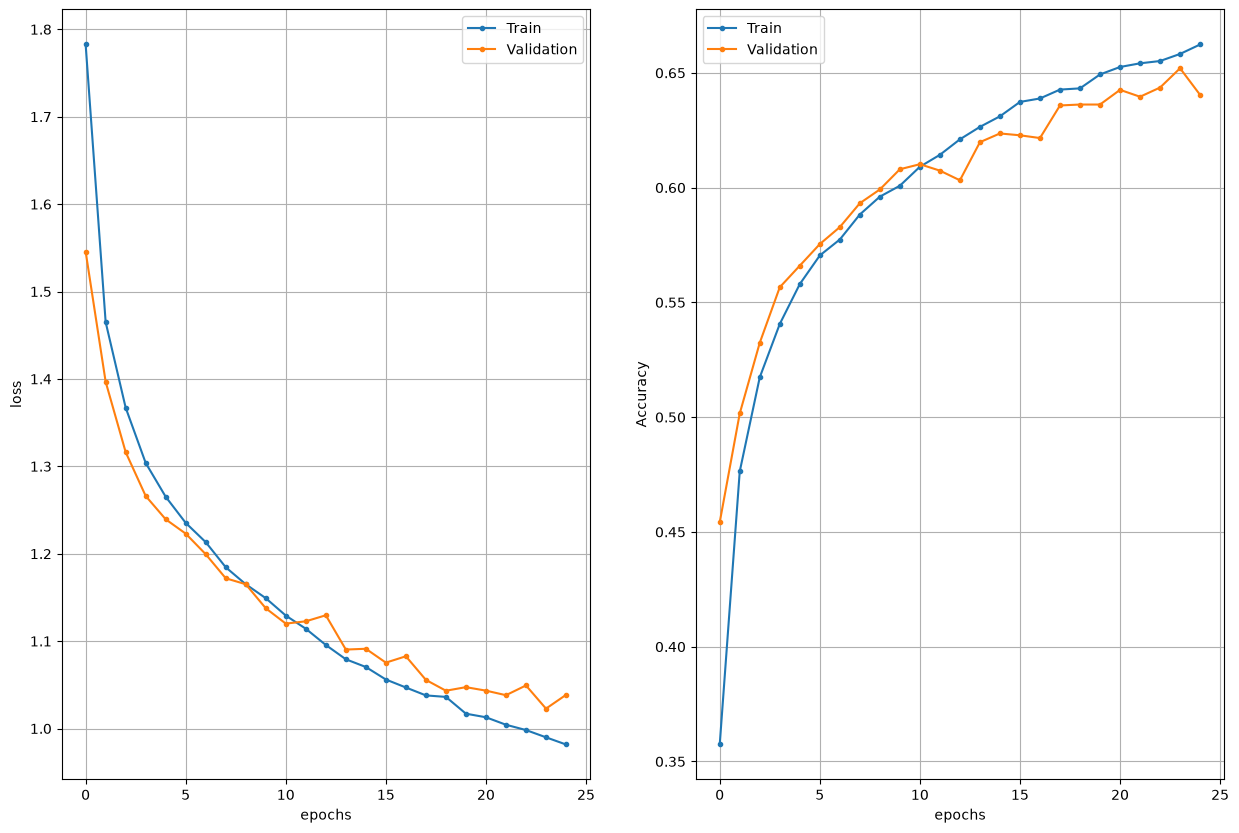

In [7]:
# Show training history (this cell is complete, nothing to implement here :-) )
h = history.history
epochs = range(len(h['loss']))

plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
plt.legend(['Train', 'Validation'])
plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                           epochs, h['val_accuracy'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])    

### Step 4: Evaluation

In this step, you have to calculate the accuracies and visualize some random samples. For the evaluation, you are going to use the test split from the dataset.

In [8]:
# Compute the labels and the predictions as sparse values
probs = model.predict(x_test, verbose=0)

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(probs, axis=1)

In [9]:
# Compute and print the accuracy for each class
for class_id, class_name in classes.items():
    mask = (y_true == class_id)
    
    acc = np.mean(y_pred[mask] == y_true[mask])
    print(class_name, acc)

plane 0.656
car 0.79
bird 0.606
cat 0.458
deer 0.416
dog 0.575
frog 0.808
horse 0.689
ship 0.7
truck 0.676


In [10]:
# Print the overall stats
ev = model.evaluate(x_test, y_test)
print('Test loss  ', ev[0])
print('Test metric', ev[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - accuracy: 0.6374 - loss: 1.0605
Test loss   1.0604510307312012
Test metric 0.6373999714851379


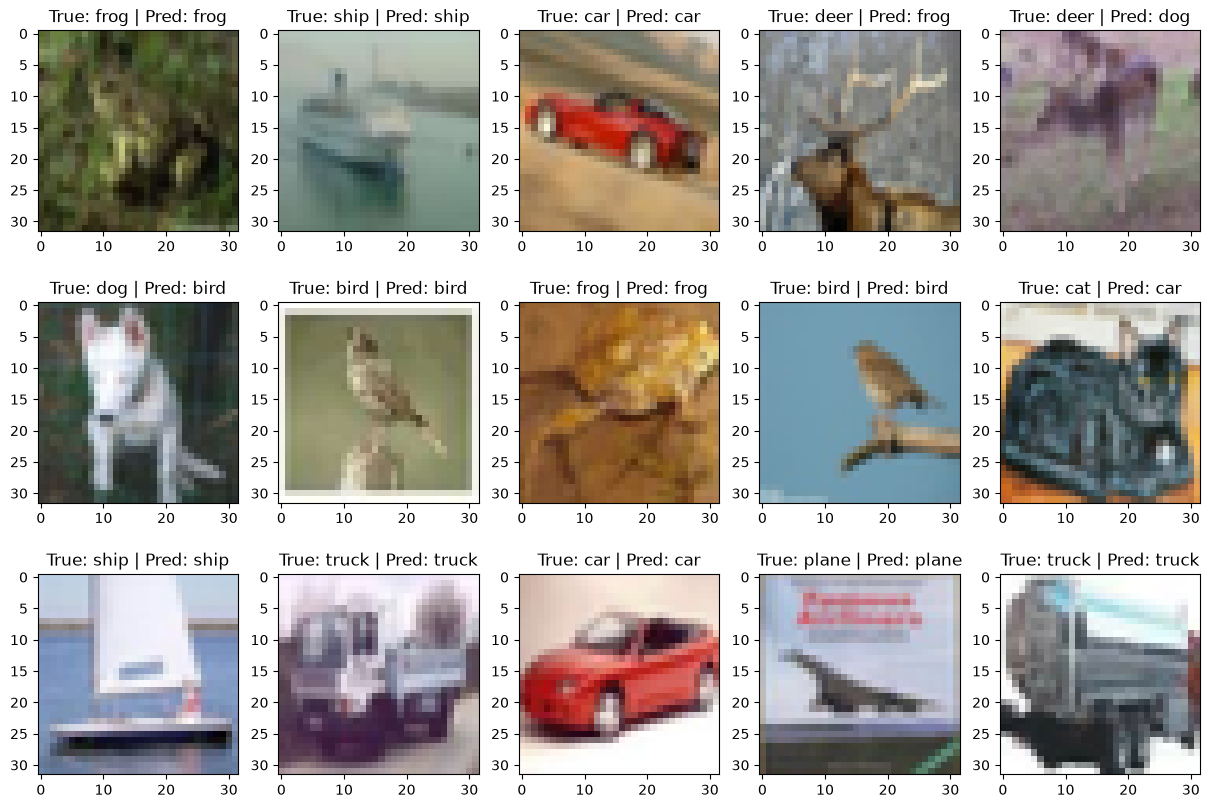

In [11]:
# Show random samples
for ii in range(15):
    # Pick a random sample
    idx = np.random.randint(0, len(x_test))
    # Show the results
    plt.subplot(3,5,ii+1), plt.imshow(x_test[idx, ...])
    plt.title('True: ' + str(classes[y_true[idx]]) + ' | Pred: ' + str(classes[y_pred[idx]]))

### Questions
* What is the overall accuracy of the classifier?
The overall accuracy appeared to be 0.6387 which is better than the basic prediction accuracy of 0.1 which represent the possibility of correct answer by blind chance as 10%
* What modifications would you do in order to improve the classification accuracy?
I think that it makes sense to work with convolutional layers parameters. Since the images are relatively small, change of kernel size wont take positive effect; the increase of filters count can work good since this can cover more specific features. Also adding additional convolution layers could work good.
* Make **one** modification (that you think can help) and train the classifier again. Does the accuracy improve?
  In the code below I haveperdormed the next modifications: added sequentially two convolutional layers more with different activation and increased twice filters quantity in the secon pair of convolutional layers.
* Compare the training and the validation accuracy. What do you observe?
  See the text block after the code below.

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 10, 10, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         8,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,666 (96.35 KB)

 Trainable params: 24,666 (96.35 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
352/352 - 133s - 377ms/step - accuracy: 0.4074 - loss: 1.6477 - val_accuracy: 0.5118 - val_loss: 1.3869
Epoch 2/25
352/352 - 136s - 386ms/step - accuracy: 0.5274 - loss: 1.3301 - val_accuracy: 0.5604 - val_loss: 1.2478
Epoch 3/25
352/352 - 134s - 381ms/step - accuracy: 0.5786 - loss: 1.1957 - val_accuracy: 0.5974 - val_loss: 1.1478
Epoch 4/25
352/352 - 134s - 382ms/step - accuracy: 0.6128 - loss: 1.1011 - val_accuracy: 0.6322 - val_loss: 1.0519
Epoch 5/25
352/352 - 135s - 383ms/step - accuracy: 0.6403 - loss: 1.0331 - val_accuracy: 0.6356 - val_loss: 1.0434
Epoch 6/25
352/352 - 135s - 385ms/step - accuracy: 0.6572 - loss: 0.9789 - val_accuracy: 0.6468 - val_loss: 1.0085
Epoch 7/25
352/352 - 134s - 381ms/step - accuracy: 0.6719 - loss: 0.9433 - val_accuracy: 0.6650 - val_loss: 0.9640
Epoch 8/25
352/352 - 135s - 382ms/step - accuracy: 0.6834 - loss: 0.9125 - val_accuracy: 0.6676 - val_loss: 0.9655
Epoch 9/25
352/352 - 135s - 384ms/step - accuracy: 0.6935 - loss: 0.8845 - val_a

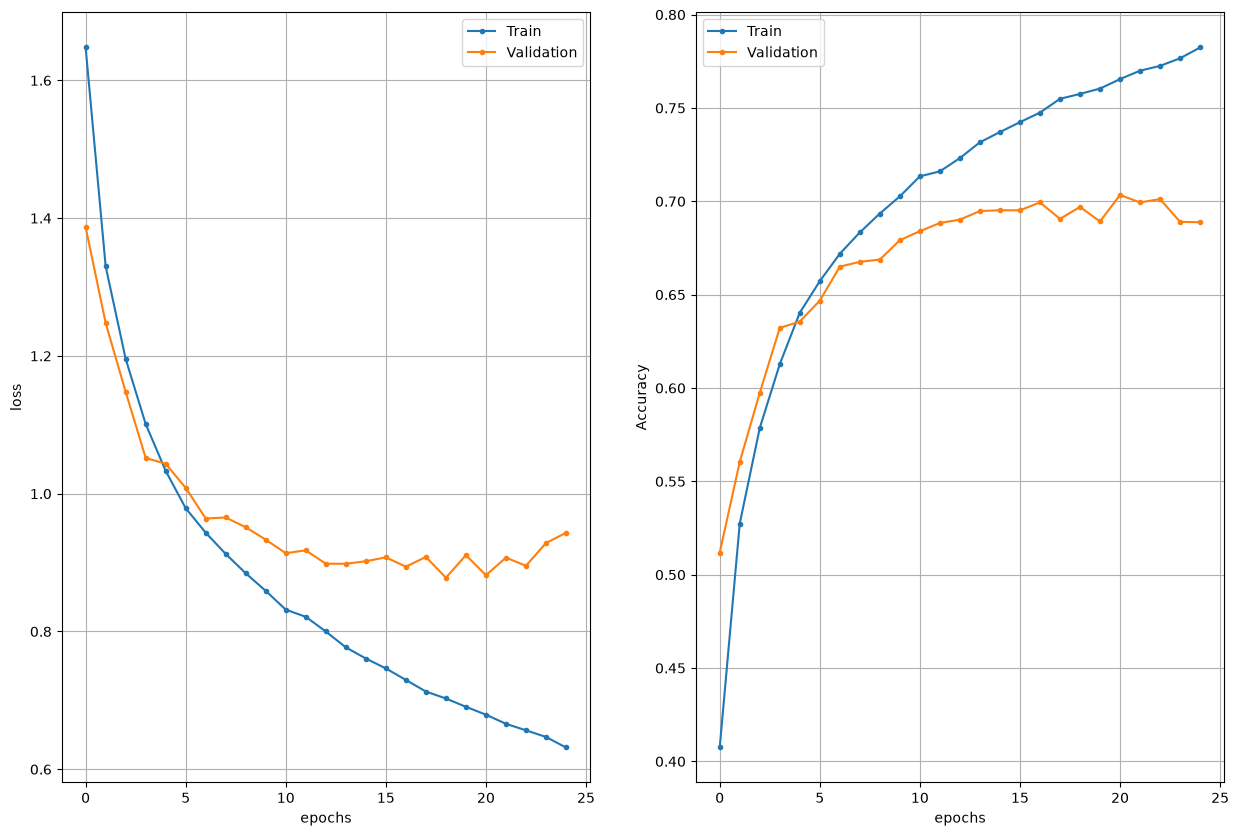

In [16]:
inputs_2 = Input(shape=(size, size, 3))
net_2 = Conv2D(16, kernel_size=(3,3), activation='relu')(inputs_2)
net_2 = Conv2D(16, kernel_size=(3,3), activation='selu')(net_2)
net_2 = MaxPooling2D(pool_size=(2,2))(net_2)
net_2 = Conv2D(32, kernel_size=(3,3), activation='relu')(net_2)
net_2 = Conv2D(32, kernel_size=(3,3), activation='selu')(net_2)
net_2 = MaxPooling2D(pool_size=(2,2))(net_2)
net_2 = Flatten()(net_2)
outputs_2 = Dense(num_classes, activation='softmax')(net_2)

model_2 = Model(inputs_2, outputs_2)
# Show the model
model_2.summary()
keras.utils.plot_model(model_2, to_file="model_2.png", show_shapes=True, show_layer_names=True)

epochs = 25
batch_size = 128

# Compile the model
model_2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
# Train the model
history_2 = model_2.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1, verbose=2)

h = history_2.history
epochs = range(len(h['loss']))

plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
plt.legend(['Train', 'Validation'])
plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                           epochs, h['val_accuracy'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])    

# Compute the labels and the predictions as sparse values
probs_2 = model_2.predict(x_test, verbose=0)

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(probs_2, axis=1)

# Compute and print the accuracy for each class
for class_id, class_name in classes.items():
    mask = (y_true == class_id)
    
    acc = np.mean(y_pred[mask] == y_true[mask])
    print(class_name, acc)

# Print the overall stats
ev = model_2.evaluate(x_test, y_test)
print('Test loss  ', ev[0])
print('Test metric', ev[1])

The results of neural network improvment are the next:
  1) The train accuracy increased from 0.6623 to 0.7824 - Pretty good and pleasant
  2) The validation accuracy increased from 0.6403 to 0.6887 - Acceptable
  3) The training time increased more than twice
This allows me to make the next conclusion:
  1) It is obviuos that at since the 6th epoch the difference between train and validation accuracy and loss started to increase drammatically. This can mean that the network sticked to the training dataset too much (at the same time loosing the ability cope with data outside training dataset). The overfitting occured.
  2) The more complicated network can perform better but withoyt further improvements it will require unappropriate resources amount compared to performance increase.
  3) There is need to cope with overfitting.